# Example of the aitlas toolbox in the context of object detection 

## Import the required packages

In [ ]:
from aitlas.datasets import xviewDataset
from aitlas.transforms import Resize
from aitlas.utils import image_loader
from aitlas.models import FasterRCNN
import matplotlib.pyplot as plt

## Visualize images and objects with bounding boxes

In [ ]:
dataset_config = {
    "data_dir": "/home/dragik/data/FAIR_EO/xview/train_images",
    "annotation_dir": "/home/dragik/data/FAIR_EO/xview/train_labels/xView_train.geojson",
}
dataset = xviewDataset(dataset_config)

print(f"Total number of patches: {len(dataset)}")

Total number of patches: 846


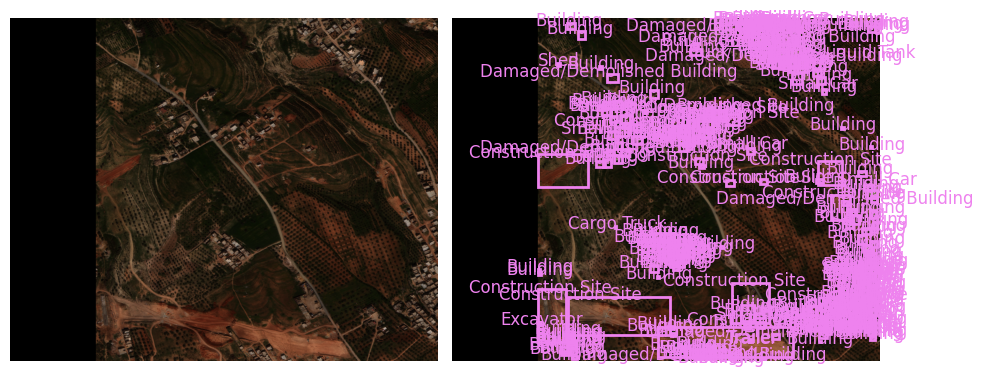

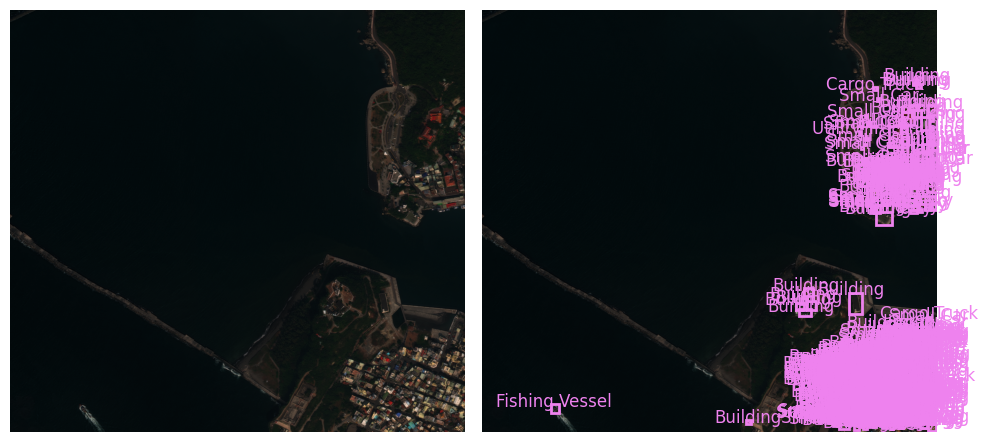

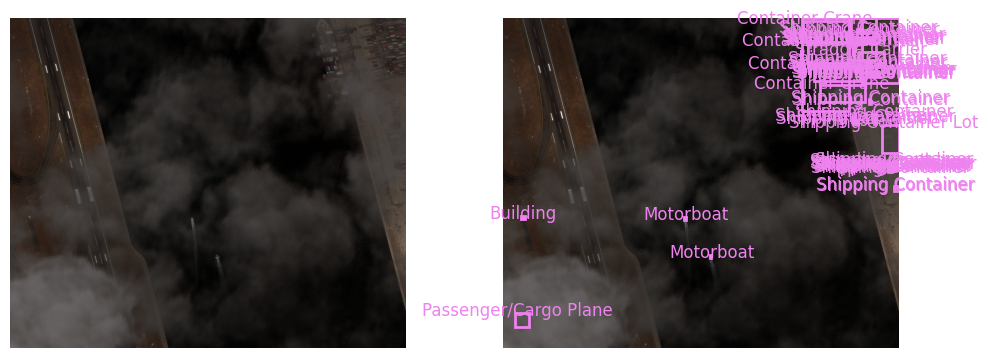

In [10]:
dataset.show_image(30);
dataset.show_image(100);
dataset.show_image(350);

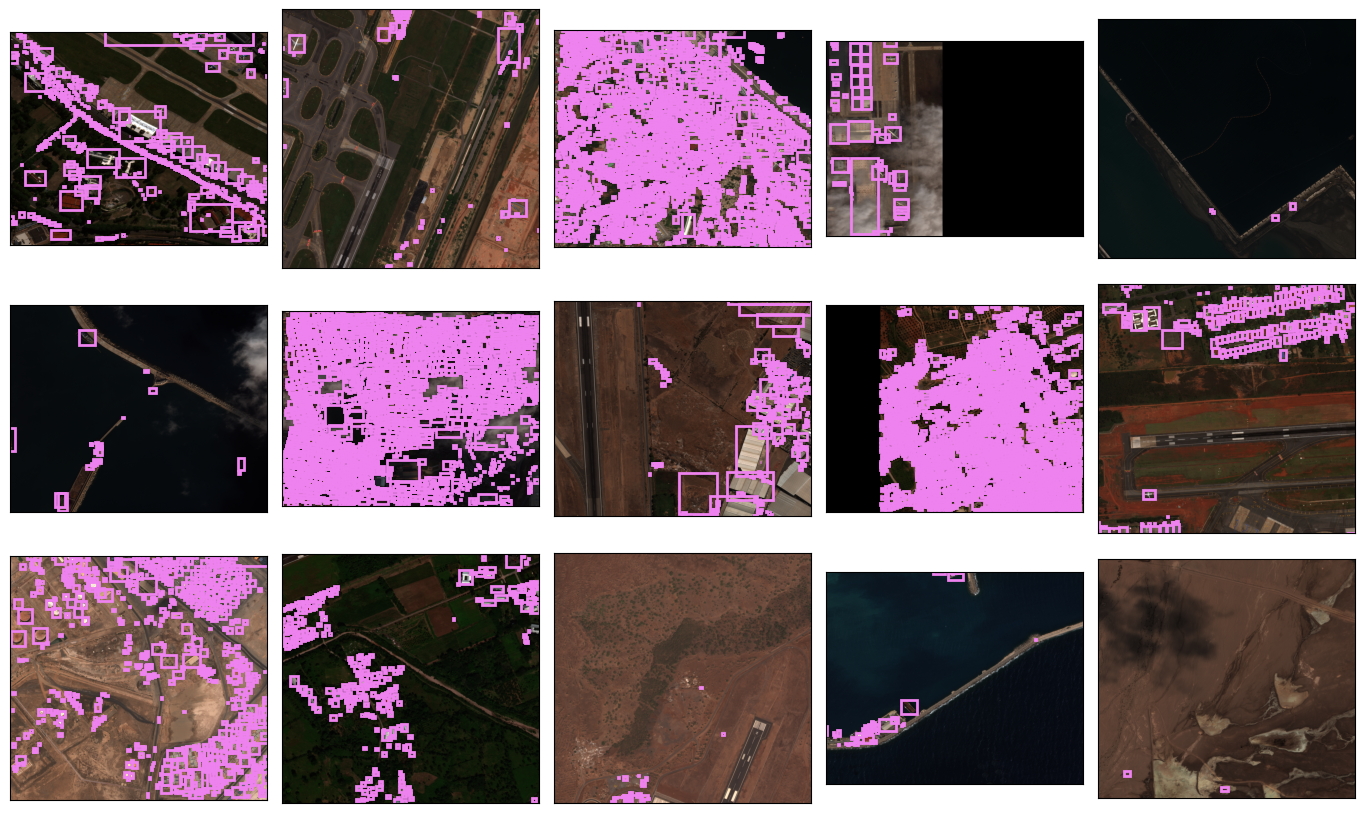

In [10]:
dataset.show_batch(15);

In [13]:
dataset.data_distribution_table()

,Label,Count
0,Fixed-wing Aircraft,74
1,Small Aircraft,368
2,Passenger/Cargo Plane,718
3,Helicopter,71
4,Passenger Vehicle,2954
...,...,...
57,Shipping Container,1589
58,Pylon,374
59,Tower,85
60,Unknown,28


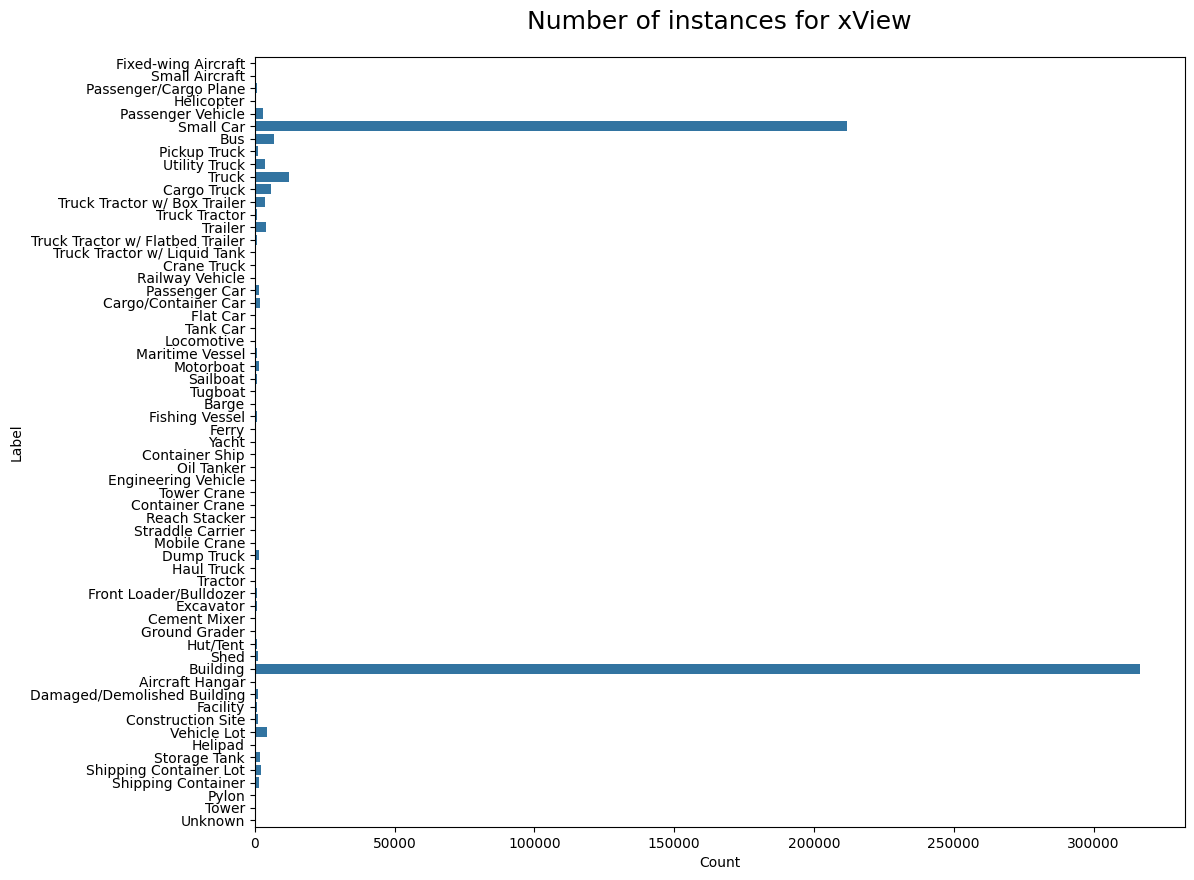

In [14]:
dataset.data_distribution_barchart();

## Load training data

In [ ]:
train_dataset_config = {
    "batch_size": 4,
    "shuffle": True,
    "num_workers": 4,
    "data_dir": "/home/dragik/data/FAIR_EO/xview/train_images",
    "annotation_dir": "/home/dragik/data/FAIR_EO/xview/train_labels/xView_train.geojson",
    "joint_transforms": ["aitlas.transforms.ResizeToTensorV2"]
}
train_dataset = xviewDataset(train_dataset_config)

print(f"Total number of train images: {len(train_dataset)}")

Total number of train images: 846


## Create the model

In [ ]:
epochs = 10
model_directory = "/home/dragik/data/FAIR_EO/experiments/xview/"
model_config = {
    "num_classes": 62,
    "learning_rate": 0.0001,
    "pretrained": True,
    "metrics": ["map"]
}

model = FasterRCNN(model_config)
model.prepare()

## Start the training

In [7]:
model.train_model(
    train_dataset=train_dataset,
    epochs=epochs,
    model_directory=model_directory,
    run_id='1'
)

2025-10-27 08:50:35,538 INFO Starting training.
training: 100%|██████████| 212/212 [04:46<00:00,  1.35s/it]
2025-10-27 08:55:22,662 INFO epoch: 1, time: 287, loss:  1.80966
testing on train set: 100%|██████████| 212/212 [04:51<00:00,  1.37s/it]
2025-10-27 09:08:26,947 INFO map:0.0011829903814941645, map_50:0.0027189392130821943, map_75:0.00077435391722247, map_small:0.0009084227494895458, map_medium:0.021227184683084488, map_large:0.009646864607930183, mar_1:0.0006777836242690682, mar_10:0.00124604522716254, mar_100:0.0015012153889983892, mar_small:0.0012215864844620228, mar_medium:0.030953343957662582, mar_large:0.017777778208255768, map_per_class:tensor(0.), tensor(0.), tensor(0.0383), tensor(0.), tensor(0.), tensor(5.5606e-05), tensor(0.), tensor(0.), tensor(0.), tensor(0.0008), tensor(0.), tensor(0.), tensor(0.), tensor(0.), tensor(0.), tensor(0.), tensor(0.), tensor(0.), tensor(0.), tensor(0.), tensor(0.), tensor(0.), tensor(0.), tensor(0.), tensor(0.), tensor(0.), tensor(0.), ten

0.9614332168942084

## Predictions

2025-10-27 12:41:41,433 INFO Loading checkpoint /home/dragik/data/FAIR_EO/experiments/xView/checkpoint.pth.tar
2025-10-27 12:41:41,724 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/experiments/xView/checkpoint.pth.tar at epoch 11


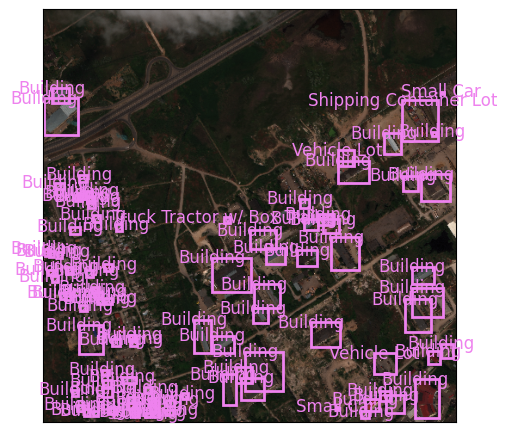

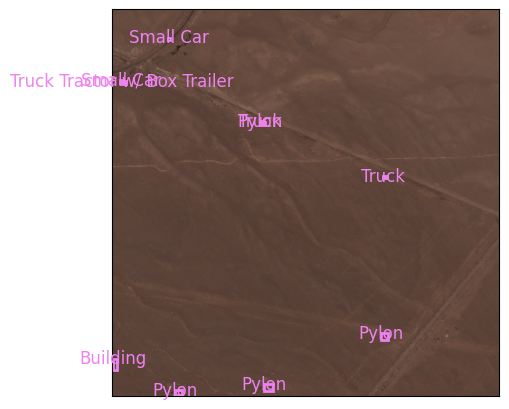

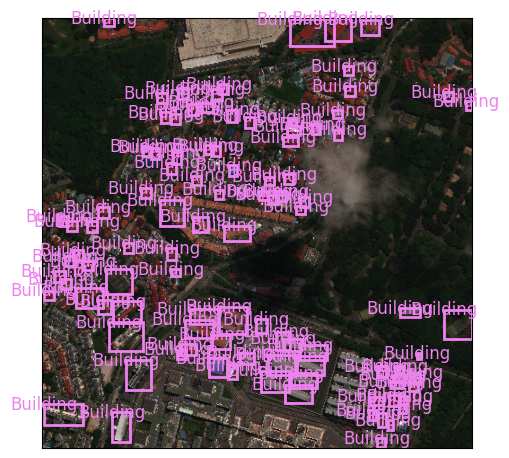

In [ ]:
model_config = {
    "num_classes": 62,
    "learning_rate": 0.0001,
    "pretrained": True,
    "metrics": ["map"]
}
model = FasterRCNN(model_config)
model.prepare()

model_path = "/home/dragik/data/FAIR_EO/experiments/xview/checkpoint.pth.tar"
labels = ["Fixed-wing Aircraft",
        "Small Aircraft",
        "Passenger/Cargo Plane",
        "Helicopter",
        "Passenger Vehicle",
        "Small Car",
        "Bus",
        "Pickup Truck",
        "Utility Truck",
        "Truck",
        "Cargo Truck",
        "Truck Tractor w/ Box Trailer",
        "Truck Tractor",
        "Trailer",
        "Truck Tractor w/ Flatbed Trailer",
        "Truck Tractor w/ Liquid Tank",
        "Crane Truck",
        "Railway Vehicle",
        "Passenger Car",
        "Cargo/Container Car",
        "Flat Car",
        "Tank Car",
        "Locomotive",
        "Maritime Vessel",
        "Motorboat",
        "Sailboat",
        "Tugboat",
        "Barge",
        "Fishing Vessel",
        "Ferry",
        "Yacht",
        "Container Ship",
        "Oil Tanker",
        "Engineering Vehicle",
        "Tower Crane",
        "Container Crane",
        "Reach Stacker",
        "Straddle Carrier",
        "Mobile Crane",
        "Dump Truck",
        "Haul Truck",
        "Tractor",
        "Front Loader/Bulldozer",
        "Excavator",
        "Cement Mixer",
        "Ground Grader",
        "Hut/Tent",
        "Shed",
        "Building",
        "Aircraft Hangar",
        "Damaged/Demolished Building",
        "Facility",
        "Construction Site",
        "Vehicle Lot",
        "Helipad",
        "Storage Tank",
        "Shipping Container Lot",
        "Shipping Container",
        "Pylon",
        "Tower",
        "Unknown",
        "Unknown"]
transform = Resize()
model.load_model(model_path)
plt.rcParams.update({'font.size': 4})

image = image_loader('/home/dragik/data/FAIR_EO/xview/val_images/11.tif')
image = image.transpose(1, 2, 0)
fig = model.detect_objects(image, labels, transform)

image = image_loader('/home/dragik/data/FAIR_EO/xview/val_images/376.tif')
image = image.transpose(1, 2, 0)
fig = model.detect_objects(image, labels, transform)

image = image_loader('/home/dragik/data/FAIR_EO/xview/val_images/1082.tif')
image = image.transpose(1, 2, 0)
fig = model.detect_objects(image, labels, transform)